---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

---

## Group 24 - AyamNutellaBear

- Geraldo Artemius 13524005
- Mikhael Yonatan 13524051
- Junior Natra Situmorang 13524055
- Reynard Nathanael 13524103
- Nicholas Luis Chandra 13524105

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Ronaldo Hotel ingin memperkirakan berapa banyak reservasi yang akan tetap berlangsung agar dapat merencanakan ketersediaan kamar. Setiap reservasi menjadi satu contoh klasifikasi biner. Label `is_canceled` bernilai 1 jika reservasi dibatalkan dan 0 jika reservasi tetap berlangsung.

## Aim

Tujuan kelompok adalah membangun dan mengevaluasi lima algoritma *supervised learning* dari awal untuk memprediksi pembatalan reservasi hotel. Kelima algoritma tersebut adalah K-Nearest Neighbors (KNN), Decision Tree Learning (DTL), Logistic Regression, Support Vector Machine (SVM), dan Naive Bayes. Kinerja setiap implementasi akan dibandingkan dengan padanannya di scikit-learn pada reservasi validasi yang sama. Model buatan kelompok kemudian digunakan untuk menghasilkan prediksi data uji bagi kompetisi Kaggle.

## Metric

Kelompok memilih **F1 untuk kelas batal** (`is_canceled = 1`) sebagai metrik utama validasi dan pemilihan konfigurasi. Sekitar 32,8% reservasi berlabel berakhir dengan pembatalan. Precision mengukur berapa banyak prediksi batal yang benar, sedangkan recall mengukur berapa banyak pembatalan aktual yang terdeteksi. F1 merangkum keduanya melalui rata-rata harmonik.

## Dataset

- `train.csv` berisi 27.373 reservasi berlabel, termasuk 8.969 reservasi yang batal.
- `test.csv` berisi 6.844 reservasi yang perlu diprediksi. Kedua berkas memiliki 17 fitur yang mencakup informasi tamu, rincian reservasi, tanggal kedatangan, dan riwayat pemesanan.
- `sample_submission.csv` menunjukkan format keluaran dengan kolom `id` dan `is_canceled`. Kolom `id` menghubungkan prediksi dengan reservasinya.

## Approach

1. Bagi data berlabel secara stratified menjadi 80% data latih dan 20% holdout. Hapus duplikat pada bagian latih, pelajari nilai imputasi dan parameter transformasi dari bagian itu, lalu terapkan ke validasi dan data uji.
2. Siapkan representasi sesuai kebutuhan model. Fitur A memuat 36 fitur setelah rekayasa fitur, standardisasi, dan encoding. PCA menyediakan alternatif 16 komponen yang mempertahankan sedikitnya 95% variansi data latih. Untuk Naive Bayes, diskretisasi dan seleksi fitur menghasilkan 21 fitur. Random oversampling menyediakan versi data latih dengan jumlah contoh kedua kelas yang sama.
3. Eksperimen yang sudah terhubung memakai logistic regression pada fitur A dengan distribusi kelas asli. Stratified 3-fold pada bagian latih digunakan untuk memilih penalti, kekuatan regularisasi, dan ambang prediksi. Perbandingan dengan scikit-learn mencakup L1, L2, dan Elastic Net pada ambang yang sama. Tabel holdout menyediakan tempat untuk hasil KNN, DTL, SVM, dan Naive Bayes saat implementasinya siap.
4. Setelah evaluasi holdout, latih ulang preprocessing dan model logistic regression terpilih menggunakan seluruh data berlabel. Terapkan transformasi tersebut ke `test.csv` dan ekspor prediksi sesuai urutan `id` pada template Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [60]:
# %pip install -q numpy pandas matplotlib seaborn scipy scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [61]:
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import KBinsDiscretizer
from scipy.stats import chi2_contingency           
from sklearn.metrics import mutual_info_score
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score 
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.naive_bayes import CategoricalNB

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

## Settings

Paths and shared constants are kept in this class.

In [62]:
class Settings:
    SEED       = 42
    SRC_DIR    = Path('..').resolve()
    DATA_DIR   = SRC_DIR / 'data'
    OUTPUT_DIR = SRC_DIR.parent / 'output'
    TARGET     = 'is_canceled'
    ID_COL     = 'id'
    VAL_SIZE   = 0.2
    FEATURE_ENGINEERING = True

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if str(CFG.SRC_DIR) not in sys.path:
    sys.path.append(str(CFG.SRC_DIR))

TARGET, ID_COL = CFG.TARGET, CFG.ID_COL

## Seed Everything

A fixed seed keeps the results reproducible.

In [63]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [64]:
train_df   = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df    = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})
sample_sub = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}  Sample submission: {sample_sub.shape}')

Train: (27373, 19)  Test: (6844, 18)  Sample submission: (6844, 2)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [65]:
summary = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'unique': train_df.nunique(),
    'missing': train_df.isna().sum(),
    'min': train_df.min(),
    'max': train_df.max(),
    'value': [train_df[c].dropna().unique()[:5].tolist() for c in train_df.columns],
})
summary

,dtype,unique,missing,min,max,value
id,str,27373,0,0003954f,fff7294f,"[57152f82, af2ec71b, 5d5469ab, d2df0369, 91d25..."
num_adults,float64,5,809,0.0,4.0,"[2.0, 3.0, 1.0, 0.0, 4.0]"
num_children,float64,6,3035,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 10.0]"
weekend_nights,int64,8,0,0,7,"[1, 2, 0, 4, 3]"
weekday_nights,int64,18,0,0,17,"[2, 1, 5, 3, 0]"
meal_package,str,4,1760,Breakfast,Room Only,"[Breakfast, Half Board, Room Only, Full Board]"
needs_parking,float64,2,1082,0.0,1.0,"[0.0, 1.0]"
room_category,str,7,1002,Type A,Type G,"[Type B, Type D, Type G, Type A, Type C]"
days_before_arrival,float64,407,1123,0.0,448.0,"[88.0, 120.0, 209.0, 93.0, 14.0]"
arrival_year,int64,2,0,2023,2024,"[2024, 2023]"


### Klasifikasi Kolom

In [66]:
NUMERICAL   = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
CATEGORICAL = ['meal_package', 'room_category', 'booking_channel']
DATE        = ['arrival_year', 'arrival_month', 'arrival_day']
BINARY      = ['needs_parking', 'is_returning_guest']
FEATURES    = NUMERICAL + CATEGORICAL + DATE + BINARY

assert set(FEATURES) | {ID_COL, TARGET} == set(train_df.columns)
assert set(train_df.columns) - set(test_df.columns) == {TARGET}

**Insights**

- Dataset train berisi 27.373 baris dan test 6.844 baris.
- `id` unik di setiap baris dan hanya digunakan untuk file submission, bukan sebagai fitur.
- Kolom dikelompokkan menjadi numerical, categorical, date, dan binary.

## Explore Data

This part covers distributions and relationships between attributes.

In [67]:
# Distribusi target
print(train_df[TARGET].value_counts())
print(train_df[TARGET].value_counts(normalize=True).round(3))

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


In [68]:
train_df[NUMERICAL + DATE].describe().T

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
prior_cancellations,27373.0,2.188288e-02,0.356353,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,27373.0,1.448873e-01,1.693652,0.0,0.0,0.0,0.0,58.0
nightly_rate_idr,25335.0,1.716980e+06,587936.773956,0.0,1338000.0,1644000.0,2019000.0,9165000.0
special_requests,24873.0,6.669481e-01,0.798363,0.0,0.0,0.0,1.0,5.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


In [69]:
# Distribusi nilai fitur kategorikal dan biner
for c in CATEGORICAL + BINARY:
    print(f'\n{c}:')
    print(train_df[c].value_counts(dropna=False))


meal_package:
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64

room_category:
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

booking_channel:
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

needs_parking:
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64

is_returning_guest:
is_returning_guest
0    26684
1      689
Name: count, dtype: int64


**Insights**

- Distribusi target 67% tidak cancel dan 33% cancel.
- Fitur numerik cenderung right skewed atau positive skewed. Kolom `prior_cancellations` dan `prior_completed_bookings` kebanyakan bernilai 0.
- Ada kategori yang langka: `Full Board` (4 baris) dan `Type E` (7 baris).

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [70]:
missing = pd.DataFrame({
    'train_missing': train_df.isna().sum(),
    'train_%': (train_df.isna().mean() * 100).round(2),
    'test_missing': test_df.isna().sum(),
    'test_%': (test_df.isna().mean() * 100).round(2),
})
missing[(missing['train_missing'] > 0) | (missing['test_missing'] > 0)]

,train_missing,train_%,test_missing,test_%
days_before_arrival,1123,4.10,290.0,4.24
meal_package,1760,6.43,442.0,6.46
needs_parking,1082,3.95,247.0,3.61
nightly_rate_idr,2038,7.45,540.0,7.89
num_adults,809,2.96,180.0,2.63
num_children,3035,11.09,747.0,10.91
room_category,1002,3.66,242.0,3.54
special_requests,2500,9.13,593.0,8.66


In [71]:
print('Id yang duplikat di train  :', train_df[ID_COL].duplicated().sum())
print('Data yang duplikat di train:', train_df.drop(columns=[ID_COL]).duplicated().sum())

Id yang duplikat di train  : 0
Data yang duplikat di train: 64


In [72]:
check = {
    'Ga ada tamu sama sekali': (train_df['num_adults'] == 0) & (train_df['num_children'] == 0),
    'Ga nginep': (train_df['weekend_nights'] + train_df['weekday_nights']) == 0,
    'Harganya < 0': train_df['nightly_rate_idr'] < 0,
    'Harganya 0 tapi bukan Complimentary': (train_df['nightly_rate_idr'] == 0) & (train_df['booking_channel'] != 'Complimentary'),
    'days_before_arrival < 0': train_df['days_before_arrival'] < 0,
}

for name, mask in check.items():
    print(f'{name:40s}: {mask.sum()}')

dates = pd.to_datetime(dict(year=train_df['arrival_year'], month=train_df['arrival_month'], day=train_df['arrival_day']), errors='coerce')
print('Data tanggal tidak valid:', dates.isna().sum())

Ga ada tamu sama sekali                 : 0
Ga nginep                               : 64
Harganya < 0                            : 0
Harganya 0 tapi bukan Complimentary     : 146
days_before_arrival < 0                 : 0
Data tanggal tidak valid: 0


In [73]:
# Deteksi outlier 
for c in NUMERICAL:
    q1, q3 = train_df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas  = q3 + 1.5 * iqr
    n_outlier = ((train_df[c] < batas_bawah) | (train_df[c] > batas_atas)).sum()
    print(f'{c:26s} IQR={iqr:>10.1f}  batas=[{batas_bawah:.1f}, {batas_atas:.1f}]  outlier={n_outlier}')

num_adults                 IQR=       0.0  batas=[2.0, 2.0]  outlier=7400
num_children               IQR=       0.0  batas=[0.0, 0.0]  outlier=2020
weekend_nights             IQR=       2.0  batas=[-3.0, 5.0]  outlier=16
weekday_nights             IQR=       2.0  batas=[-2.0, 6.0]  outlier=258
days_before_arrival        IQR=     109.0  batas=[-146.5, 289.5]  outlier=916
prior_cancellations        IQR=       0.0  batas=[0.0, 0.0]  outlier=241
prior_completed_bookings   IQR=       0.0  batas=[0.0, 0.0]  outlier=600
nightly_rate_idr           IQR=  681000.0  batas=[316500.0, 3040500.0]  outlier=1144
special_requests           IQR=       1.0  batas=[-1.5, 2.5]  outlier=563


In [74]:
print(train_df['num_children'].value_counts().sort_index())
print(train_df['weekday_nights'].value_counts().sort_index().tail())

num_children
0.0     22318
1.0      1221
2.0       780
3.0        16
9.0         2
10.0        1
Name: count, dtype: int64
weekday_nights
13    3
14    6
15    9
16    2
17    2
Name: count, dtype: int64


**Insights**

- Missing values ada di 8 kolom (sekitar 3–11%) dengan proporsi yang mirip di train dan test.
- Duplikasi tidak ada `id` ganda, tetapi ada 64 baris yang identik di semua kolom lain.
- Harga 0 tetapi bukan Complimentary: 146 baris.
- Tidak ada tamu 0, harga negatif, `days_before_arrival` negatif, ataupun tanggal yang tidak valid.
- Kolom dengan IQR = 0 (`num_adults`, `num_children`, `prior_cancellations`, `prior_completed_bookings`) tidak dapat dinilai dengan IQR, karena semua nilai selain nilai paling umum akan dianggap outlier. 
- Ada nilai yang tidak realistis yaitu `num_children` = 9 dan 10, yang melompat jauh dari nilai 3.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [75]:
train_set, val_set = train_test_split(
    train_df,
    test_size=CFG.VAL_SIZE,
    stratify=train_df[TARGET],
    random_state=CFG.SEED,
)

train_set = train_set.reset_index(drop=True)
val_set   = val_set.reset_index(drop=True)
test_set  = test_df.copy()
train_raw = train_set.copy()
val_raw = val_set.copy()

print(f'Train: {train_set.shape}  Val: {val_set.shape}  Test: {test_set.shape}')
print('Proporsi target train:', train_set[TARGET].value_counts(normalize=True).round(3).to_dict())
print('Proporsi target val  :', val_set[TARGET].value_counts(normalize=True).round(3).to_dict())

Train: (21898, 19)  Val: (5475, 19)  Test: (6844, 18)
Proporsi target train: {0: 0.672, 1: 0.328}
Proporsi target val  : {0: 0.672, 1: 0.328}


**Insights**

- Split dilakukan secara *stratified* (stratified random sampling) sehingga proporsi kelas 67:33 sama di train dan validation.
- Semua statistik pada tahap Data Preparation dihitung dari `train_set` saja.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [76]:
print('Jumlah fitur yang dipakai:', len(FEATURES))
print('Fitur:', FEATURES)
print('Bukan fitur:', [ID_COL, TARGET])

Jumlah fitur yang dipakai: 17
Fitur: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'room_category', 'booking_channel', 'arrival_year', 'arrival_month', 'arrival_day', 'needs_parking', 'is_returning_guest']
Bukan fitur: ['id', 'is_canceled']


**Insights**

- Semua 17 fitur digunakan. 
- `id` tidak dipakai sebagai fitur karena hanya pengenal unik, tetapi tetap disimpan untuk file submission.
- Tidak dilakukan sampling karena ukuran data masih kecil untuk diproses. Seleksi record hanya berupa penghapusan duplikat di `train_set`.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Duplicates

This part covers repeated records.

In [77]:
before = len(train_set)

train_set = train_set.drop_duplicates(subset=train_set.columns.drop(ID_COL), keep='first').reset_index(drop=True)

print(f'Duplikat dihapus dari train_set: {before - len(train_set)}')
print(f'Jumlah baris train_set sekarang: {train_set.shape}')

Duplikat dihapus dari train_set: 40
Jumlah baris train_set sekarang: (21858, 19)


**Insights**

- Duplikat dihapus karena baris yang identik di semua kolom (selain `id`) membuat pola tertentu tercatat lebih dari sekali. Baris yang duplikat di drop agar tidak menimbulkan bias pada hasil analisis dan tidak membuat overfitting.
- Penghapusan hanya dilakukan di `train_set`. 

### Missing Values

This part covers missing values, if any.

In [78]:
NUMERICAL_MISSING   = ['num_adults', 'num_children', 'days_before_arrival', 'nightly_rate_idr', 'special_requests']
CATEGORICAL_MISSING = ['meal_package', 'room_category', 'needs_parking']

fill = {c: train_set[c].median() for c in NUMERICAL_MISSING}
fill.update({c: train_set[c].mode().iloc[0] for c in CATEGORICAL_MISSING})
print(fill)

train_set = train_set.fillna(fill)
val_set   = val_set.fillna(fill)
test_set  = test_set.fillna(fill)

for name, df in [('train', train_set), ('val', val_set), ('test', test_set)]:
    print(f'Sisa missing {name}: {df.isna().sum().sum()}')

{'num_adults': np.float64(2.0), 'num_children': np.float64(0.0), 'days_before_arrival': np.float64(57.0), 'nightly_rate_idr': np.float64(1647000.0), 'special_requests': np.float64(0.0), 'meal_package': 'Breakfast', 'room_category': 'Type B', 'needs_parking': np.float64(0.0)}
Sisa missing train: 0
Sisa missing val: 0
Sisa missing test: 0


**Insights**

- Data Numerik diisi median. Jika pakai mean, akan ikut tertarik oleh nilai ekstrem, sedangkan median tidak.
- Data Kategorikal dan biner diisi modus. Karena string tidak memiliki rata-rata atau nilai tengah. 

### Outliers

This part covers values far from the rest of the data.

In [79]:
def replace_child_outliers(df, median):
    df = df.copy()
    df.loc[df['num_children'] > 3, 'num_children'] = median
    return df

child_median = train_set['num_children'].median()   

for name, df in [('train', train_set), ('val', val_set), ('test', test_set)]:
    print(f'{name} num_children > 3: {(df["num_children"] > 3).sum()}')

train_set = replace_child_outliers(train_set, child_median)
val_set = replace_child_outliers(val_set, child_median)
test_set = replace_child_outliers(test_set, child_median)

train num_children > 3: 3
val num_children > 3: 0
test num_children > 3: 0


**Insights**

- Outlier (`num_children` ≥ 9) diganti dengan nilai median dari `train_set`. Menggunakan batas > 3 dipilih karena nilai 3.


Batas > 3 mempertahankan nilai 3 yang masih muncul pada data latih dan mengganti nilai 9 serta 10 dengan median.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [80]:
INT_COLS = ['num_adults', 'num_children', 'special_requests', 'days_before_arrival', 'needs_parking']

for df in (train_set, val_set, test_set):
    df[INT_COLS] = df[INT_COLS].astype(int)

In [81]:
for name, df in [('train', train_set), ('val', val_set), ('test', test_set)]:
    print(f'{name:5s} shape={df.shape}  missing={df.isna().sum().sum()}  num_children max={df["num_children"].max()}')

print('Baris identik setelah imputasi di train_set:', train_set.drop(columns=[ID_COL]).duplicated().sum())
train_set.dtypes

train shape=(21858, 19)  missing=0  num_children max=3
val   shape=(5475, 19)  missing=0  num_children max=3
test  shape=(6844, 18)  missing=0  num_children max=3
Baris identik setelah imputasi di train_set: 54


id                              str
num_adults                    int64
num_children                  int64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking                 int64
room_category                   str
days_before_arrival           int64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests              int64
is_canceled                   int64
dtype: object

In [82]:
def correct_guest_counts(df, adult_mode):
    df = df.copy()
    zero_guest = (df['num_adults'] == 0) & (df['num_children'] == 0)
    df.loc[zero_guest, 'num_adults'] = adult_mode
    return df

adult_mode = train_set['num_adults'].mode().iloc[0]

for name, df in [('train', train_set), ('val', val_set), ('test', test_set)]:
    zero_guest = (df['num_adults'] == 0) & (df['num_children'] == 0)
    print(f'{name} booking tidak valid karena ga ada orang: {zero_guest.sum()}')

train_set = correct_guest_counts(train_set, adult_mode)
val_set = correct_guest_counts(val_set, adult_mode)
test_set = correct_guest_counts(test_set, adult_mode)

train booking tidak valid karena ga ada orang: 0
val booking tidak valid karena ga ada orang: 1
test booking tidak valid karena ga ada orang: 0


In [83]:
# Gabungkan langkah cleaning untuk dipakai kembali oleh pipeline.
def clean_reservations(raw_fit, raw_eval):
    train = raw_fit.drop_duplicates(subset=raw_fit.columns.drop(ID_COL))
    fill = train[NUMERICAL_MISSING].median().to_dict()
    fill.update(train[CATEGORICAL_MISSING].mode().iloc[0].to_dict())
    child_median = train['num_children'].median()
    adult_mode = train.fillna(fill)['num_adults'].mode().iloc[0]

    # Jalankan fungsi persiapan yang sudah dipakai pada Data Preparation.
    frames = []
    for df in (train, raw_eval):
        df = replace_child_outliers(df.fillna(fill), child_median)
        df[INT_COLS] = df[INT_COLS].astype(int)
        frames.append(correct_guest_counts(df, adult_mode))
    train, other = frames
    return train, other

**Insights**

- Baris dengan 0 malam dan baris dengan harga 0 di luar channel Complimentary tidak diubah.
- Baris yang menjadi identik setelah imputasi tidak dihapus, karena kemiripannya berasal dari nilai hasil imputasi, bukan dari data asli.
- Ditemukan 1 booking tanpa orang (`num_adults` = 0 dan `num_children` = 0) pada `val_set`.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [84]:
ROOM_MEDIAN_RATE = train_set.groupby('room_category')['nightly_rate_idr'].median()
RATE_MEDIAN      = train_set['nightly_rate_idr'].median()
LAST_MINUTE_DAYS = 7

def construct_attributes(df, room_rates=ROOM_MEDIAN_RATE, rate_median=RATE_MEDIAN):
    df = df.copy()
    if not CFG.FEATURE_ENGINEERING:
        return df

    df['has_children'] = (df['num_children'] > 0).astype(int)
    df['no_cost'] = (df['nightly_rate_idr'] == 0).astype(int)
    df['room_price_position'] = (df['nightly_rate_idr'] / df['room_category'].map(room_rates)).fillna(1.0)
    df['high_rate_no_request'] = ((df['nightly_rate_idr'] > rate_median) & (df['special_requests'] == 0)).astype(int)
    df['has_cancel'] = (df['prior_cancellations'] > 0).astype(int)
    
    arrival_date = pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']))
    booking_date = arrival_date - pd.to_timedelta(df['days_before_arrival'], unit='D')
    
    df['week_day']         = arrival_date.dt.dayofweek
    df['booking_month']    = booking_date.dt.month
    df['booking_week_day'] = booking_date.dt.dayofweek
    df['online_last_minute'] = ((df['booking_channel'] == 'Online Travel Agent') & (df['days_before_arrival'] <= LAST_MINUTE_DAYS)).astype(int)
    df['no_special_requests'] = (df['special_requests'] == 0).astype(int)
    df['multiple_requests'] = (df['special_requests'] >= 2).astype(int)
    df['rate_no_requests'] = df['nightly_rate_idr'] * df['no_special_requests']
    df['online_no_requests'] = (df['booking_channel'] == 'Online Travel Agent').astype(int) * df['no_special_requests']

    lead_band = pd.cut(df['days_before_arrival'], [-1, 7, 30, 90, 180, np.inf]).astype(str)
    request_band = df['special_requests'].clip(upper=3).astype(str)
    df['channel_lead_band'] = df['booking_channel'] + '_' + lead_band
    df['channel_request_band'] = df['booking_channel'] + '_' + request_band
    df['arrival_month_category'] = df['arrival_month'].astype(str)

    return df

train_set = construct_attributes(train_set)
val_set   = construct_attributes(val_set)
test_set  = construct_attributes(test_set)

NEW_FEATURES = ['has_children', 'no_cost', 'room_price_position', 'high_rate_no_request', 'has_cancel',
                'week_day', 'booking_month', 'booking_week_day', 'online_last_minute',
                'no_special_requests', 'multiple_requests', 'rate_no_requests', 'online_no_requests',
                'channel_lead_band', 'channel_request_band', 'arrival_month_category']
NEW_FEATURES = [c for c in NEW_FEATURES if c in train_set.columns]
if CFG.FEATURE_ENGINEERING:
    display(train_set[NEW_FEATURES].describe().T)
else:
    print('Feature engineering dinonaktifkan.')

,count,mean,std,min,25%,50%,75%,max
has_children,21858.0,0.073657,0.261218,0.0,0.000000,0.0,0.000000e+00,1.000000e+00
no_cost,21858.0,0.014640,0.120109,0.0,0.000000,0.0,0.000000e+00,1.000000e+00
room_price_position,21858.0,0.998027,0.285212,0.0,0.826683,1.0,1.152743e+00,5.713840e+00
high_rate_no_request,21858.0,0.219050,0.413612,0.0,0.000000,0.0,0.000000e+00,1.000000e+00
has_cancel,21858.0,0.008372,0.091118,0.0,0.000000,0.0,0.000000e+00,1.000000e+00
week_day,21858.0,3.079559,2.067452,0.0,1.000000,3.0,5.000000e+00,6.000000e+00
booking_month,21858.0,6.183137,3.553176,1.0,3.000000,7.0,9.000000e+00,1.200000e+01
booking_week_day,21858.0,2.983301,2.011780,0.0,1.000000,3.0,5.000000e+00,6.000000e+00
online_last_minute,21858.0,0.094290,0.292239,0.0,0.000000,0.0,0.000000e+00,1.000000e+00
no_special_requests,21858.0,0.555129,0.496963,0.0,0.000000,1.0,1.000000e+00,1.000000e+00


In [85]:
if CFG.FEATURE_ENGINEERING:
    for c in ['has_children', 'no_cost', 'high_rate_no_request', 'has_cancel', 'online_last_minute', 'week_day', 'booking_month', 'booking_week_day']:
        print(train_set.groupby(c)[TARGET].agg(['mean', 'count']).round(3), '\n')

    print(train_set.groupby(pd.qcut(train_set['room_price_position'], 4, duplicates='drop'), observed=True)[TARGET].agg(['mean', 'count']).round(3))

               mean  count
has_children              
0             0.325  20248
1             0.366   1610 

          mean  count
no_cost              
0        0.332  21538
1        0.006    320 

                       mean  count
high_rate_no_request              
0                     0.260  17070
1                     0.568   4788 

             mean  count
has_cancel              
0           0.330  21675
1           0.044    183 

                     mean  count
online_last_minute              
0                   0.350  19797
1                   0.111   2061 

           mean  count
week_day              
0         0.305   3235
1         0.323   2981
2         0.324   3115
3         0.319   2712
4         0.323   2847
5         0.318   3230
6         0.372   3738 

                mean  count
booking_month              
1              0.416   2483
2              0.412   2386
3              0.401   1785
4              0.408   1885
5              0.354   1375
6              0.

**Insights**

- **`room_price_position`**: harga per malam dibagi median harga kategori kamar yang sama. 
- **`high_rate_no_request`**: booking dengan harga di atas median tanpa permintaan khusus. Tingkat pembatalannya 56,8%, jauh di atas rata-rata 33%.
- **`online_last_minute`**: booking melalui Online Travel Agent yang dibuat paling lambat 7 hari sebelum kedatangan. Tingkat pembatalannya hanya 11,1%.
- **`no_cost`** dan **`has_cancel`**: menandai menginap gratis (cancel 0,6%) dan tamu yang pernah membatalkan (cancel 4,4%).
- **`week_day`**, **`booking_month`**, dan **`booking_week_day`**: tanggal booking dihitung dari tanggal kedatangan - `days_before_arrival`.
- **`no_special_requests`**: menandai booking tanpa permintaan khusus.
- **`multiple_requests`**: menandai booking dengan minimal dua permintaan khusus.
- **`rate_no_requests`**: harga per malam untuk booking tanpa permintaan khusus, bernilai 0 jika ada permintaan khusus.
- **`online_no_requests`**: menandai booking melalui Online Travel Agent tanpa permintaan khusus.
- **`channel_lead_band`**: jalur pemesanan digabung dengan kelompok jeda kedatangan 0–7, 8–30, 31–90, 91–180, dan lebih dari 180 hari.
- **`channel_request_band`**: jalur pemesanan digabung dengan kelompok jumlah permintaan khusus 0, 1, 2, dan minimal 3.
- **`arrival_month_category`**: bulan kedatangan sebagai kategori untuk one-hot encoding.


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [86]:
SCALES = NUMERICAL + DATE + ['room_price_position', 'week_day', 'booking_month', 'booking_week_day', 'no_special_requests', 'multiple_requests', 'rate_no_requests', 'online_no_requests']
BINS = BINARY + ['has_children', 'no_cost', 'has_cancel', 'high_rate_no_request', 'online_last_minute']
SCALES = [c for c in SCALES if c in train_set.columns]
BINS = [c for c in BINS if c in train_set.columns]

def scale_features(df, scaler):
    df = df.copy()
    df[SCALES] = scaler.transform(df[SCALES])
    return df

scaler = StandardScaler()
scaler.fit(train_set[SCALES])

train_scaled = scale_features(train_set, scaler)
val_scaled = scale_features(val_set, scaler)
test_scaled = scale_features(test_set, scaler)

train_scaled[SCALES].describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
num_adults,0.0,1.0,-3.62,4.20
num_children,0.0,1.0,-0.26,7.39
weekend_nights,-0.0,1.0,-0.94,7.06
weekday_nights,0.0,1.0,-1.55,10.42
days_before_arrival,-0.0,1.0,-1.00,4.32
prior_cancellations,0.0,1.0,-0.06,36.33
prior_completed_bookings,-0.0,1.0,-0.09,35.55
nightly_rate_idr,-0.0,1.0,-3.04,13.21
special_requests,-0.0,1.0,-0.77,5.59
arrival_year,0.0,1.0,-2.13,0.47


**Insight**

- Pakai standardisasi menggunakan z score, bukan min max normalization karena outlier dari dataset awal masih dipertahankan.
- Dilakukan scaling karena data terlalu bervariasi dan beragam. 
- Mean dan std hanya dihitung dari `train_set` saja, supaya hasil dari val_set dan test_set tidak bocor.

### Encoding

This part covers the numeric representation of categorical attributes.

In [87]:
MIN_COUNT = 20

meal_map = {'Full Board': 'Half Board'}   
room_counts = train_set['room_category'].value_counts()
rare_rooms = room_counts[room_counts < MIN_COUNT].index.tolist()
print('Kamar yang sedikit:', rare_rooms, '| Full Board di train:', (train_set['meal_package'] == 'Full Board').sum())

def merging(df, rare_rooms=rare_rooms):
    df['meal_package'] = df['meal_package'].replace(meal_map)
    df['room_category'] = df['room_category'].replace({r: 'Type Other' for r in rare_rooms})
    return df

for df in (train_set, val_set, test_set, train_scaled, val_scaled, test_scaled):
    merging(df)

Kamar yang sedikit: ['Type E'] | Full Board di train: 4


In [88]:
MEALS = ['Room Only', 'Breakfast', 'Half Board']
ONEHOTRESULT = ['room_category', 'booking_channel']
if CFG.FEATURE_ENGINEERING:
    ONEHOTRESULT += ['channel_lead_band', 'channel_request_band', 'arrival_month_category']

meal_encoder = OrdinalEncoder(categories=[MEALS])
onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
meal_encoder.fit(train_scaled[['meal_package']])
onehot.fit(train_scaled[ONEHOTRESULT])

def onehotencode(df, meal_encoder=meal_encoder, onehot=onehot):
    df = df.copy()
    df['meal_package'] = meal_encoder.transform(df[['meal_package']])
    oh = pd.DataFrame(onehot.transform(df[ONEHOTRESULT]), columns=onehot.get_feature_names_out(ONEHOTRESULT), index=df.index)
    return pd.concat([df.drop(columns=ONEHOTRESULT), oh], axis=1)

train_a, val_a, test_a = onehotencode(train_scaled), onehotencode(val_scaled), onehotencode(test_scaled)

NB_EXCLUDED = ['no_special_requests', 'multiple_requests', 'rate_no_requests', 'online_no_requests', 'channel_lead_band', 'channel_request_band', 'arrival_month_category']
nb_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
nb_encoder.fit(train_set[CATEGORICAL])

def ordinalencode(df):
    df = df.drop(columns=NB_EXCLUDED, errors='ignore').copy()
    df[CATEGORICAL] = nb_encoder.transform(df[CATEGORICAL]).astype(int)
    return df

train_b, val_b, test_b = ordinalencode(train_set), ordinalencode(val_set), ordinalencode(test_set)

print('One Hot Encoding:', train_a.shape, val_a.shape, test_a.shape)
print('Ordinal Encoding:', train_b.shape, val_b.shape, test_b.shape)
print(onehot.get_feature_names_out(ONEHOTRESULT))

One Hot Encoding: (21858, 94) (5475, 94) (6844, 93)
Ordinal Encoding: (21858, 28) (5475, 28) (6844, 27)
['room_category_Type A' 'room_category_Type B' 'room_category_Type C'
 'room_category_Type D' 'room_category_Type F' 'room_category_Type G'
 'room_category_Type Other' 'booking_channel_Airline'
 'booking_channel_Complimentary' 'booking_channel_Corporate'
 'booking_channel_Offline Agent' 'booking_channel_Online Travel Agent'
 'channel_lead_band_Airline_(-1.0, 7.0]'
 'channel_lead_band_Airline_(30.0, 90.0]'
 'channel_lead_band_Airline_(7.0, 30.0]'
 'channel_lead_band_Complimentary_(-1.0, 7.0]'
 'channel_lead_band_Complimentary_(180.0, inf]'
 'channel_lead_band_Complimentary_(30.0, 90.0]'
 'channel_lead_band_Complimentary_(7.0, 30.0]'
 'channel_lead_band_Complimentary_(90.0, 180.0]'
 'channel_lead_band_Corporate_(-1.0, 7.0]'
 'channel_lead_band_Corporate_(180.0, inf]'
 'channel_lead_band_Corporate_(30.0, 90.0]'
 'channel_lead_band_Corporate_(7.0, 30.0]'
 'channel_lead_band_Corporate_(90

In [89]:
# Gabungkan pembentukan fitur, scaling, dan encoding untuk pipeline.
def transform_features_a(train, other):
    room_rates = train.groupby('room_category')['nightly_rate_idr'].median()
    rate_median = train['nightly_rate_idr'].median()
    train = construct_attributes(train, room_rates, rate_median)
    other = construct_attributes(other, room_rates, rate_median)

    scaler = StandardScaler().fit(train[SCALES])
    counts = train['room_category'].value_counts()
    rare = counts[counts < MIN_COUNT].index
    train = merging(scale_features(train, scaler), rare)
    other = merging(scale_features(other, scaler), rare)

    meal = OrdinalEncoder(categories=[MEALS]).fit(train[['meal_package']])
    nominal = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train[ONEHOTRESULT])
    train = onehotencode(train, meal, nominal)
    other = onehotencode(other, meal, nominal)
    return train, other

**Insights**

- `Full Board` (4 baris) dan beberapa kategori kamar (kurang dari 20 baris di `train_set`) terlalu sedikit untuk digunakan dalam training. `Full Board` digabung ke `Half Board` karena merupakan paket terdekat dalam urutan, sedangkan kategori kamar yang sedikit digabung menjadi `Type Other`.
- `room_category` dan `booking_channel` dilakukan one hot encoding karena kedua kolom tidak memiliki urutan. 
- `meal_package` dilakukan ordinal encoding karena memiliki urutan berdasarkan jumlah makanan yang termasuk (Room Only < Breakfast < Half Board), sehingga ordinal encoding mempertahankan informasi urutan dalam satu kolom.

### Data Discretization

In [90]:
BIN_COLS = ['days_before_arrival', 'nightly_rate_idr', 'room_price_position']
BIN_COLS = [c for c in BIN_COLS if c in train_b.columns]
COUNT_COLS = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'special_requests', 'prior_cancellations', 'prior_completed_bookings']

def count_caps(df):
    caps = {}
    for c in COUNT_COLS:
        freq = df[c].value_counts().sort_index()
        mode_val = freq.idxmax()                                              # nilai paling umum
        rare_tail = freq[(freq.index > mode_val) & (freq < MIN_COUNT)].index
        if len(rare_tail):
            caps[c] = freq.index[freq.index < rare_tail.min()].max()          
        else:
            caps[c] = freq.index.max()
    return caps

def apply_discretization(df, discretizer, caps):
    df = df.copy()
    df[BIN_COLS] = discretizer.transform(df[BIN_COLS]).astype(int)
    for c, cap in caps.items():
        df[c] = df[c].clip(upper=cap)
    return df

discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
discretizer.fit(train_b[BIN_COLS])

for c, edges in zip(BIN_COLS, discretizer.bin_edges_):
    print(f'{c:22s}', np.round(edges, 2))

batas_atas = count_caps(train_b)
print('Batas atas kolom hitungan:', batas_atas)

train_nb = apply_discretization(train_b, discretizer, batas_atas)
val_nb   = apply_discretization(val_b, discretizer, batas_atas)
test_nb  = apply_discretization(test_b, discretizer, batas_atas)

days_before_arrival    [  0.  12.  41.  75. 147. 448.]
nightly_rate_idr       [      0. 1298000. 1562000. 1746000. 2104000. 9165000.]
room_price_position    [0.   0.79 0.93 1.03 1.2  5.71]
Batas atas kolom hitungan: {'num_adults': np.int64(3), 'num_children': np.int64(2), 'weekend_nights': np.int64(5), 'weekday_nights': np.int64(10), 'special_requests': np.int64(4), 'prior_cancellations': np.int64(3), 'prior_completed_bookings': np.int64(6)}


In [91]:
FEATURES_NB = [c for c in train_nb.columns if c not in (ID_COL, TARGET)]
train_nb[FEATURES_NB].nunique().sort_values(ascending=False)

arrival_day                 31
arrival_month               12
booking_month               12
weekday_nights              11
room_category                7
week_day                     7
prior_completed_bookings     7
booking_week_day             7
weekend_nights               6
days_before_arrival          5
room_price_position          5
special_requests             5
nightly_rate_idr             5
booking_channel              5
num_adults                   4
prior_cancellations          4
meal_package                 3
num_children                 3
arrival_year                 2
needs_parking                2
has_children                 2
is_returning_guest           2
has_cancel                   2
high_rate_no_request         2
no_cost                      2
online_last_minute           2
dtype: int64

**Insights**

- Menggunakan equal frequency binning karena binning berdasarkan kuantil memastikan setiap bin memiliki jumlah data yang cukup.

### Feature Selection

In [92]:
FEATURES_NB = [c for c in train_nb.columns if c not in (ID_COL, TARGET)]

rows = []
for c in FEATURES_NB:
    table = pd.crosstab(train_nb[c], train_nb[TARGET])            # contingency table fitur × target
    chi2_stat, p_value, dof, _ = chi2_contingency(table)
    mi = mutual_info_score(train_nb[c], train_nb[TARGET])
    rows.append({'feature': c, 'chi2': chi2_stat, 'dof': dof, 'p_value': p_value, 'mutual_info': mi})

fs_scores = pd.DataFrame(rows).sort_values('mutual_info', ascending=False).reset_index(drop=True)
fs_scores

,feature,chi2,dof,p_value,mutual_info
0,days_before_arrival,4130.767636,4,0.000000e+00,0.094434
1,special_requests,1428.241455,4,5.196226e-308,0.037095
2,high_rate_no_request,1604.540445,1,0.000000e+00,0.034942
3,arrival_month,912.088452,11,1.561280e-188,0.024802
4,arrival_year,732.101347,1,3.128064e-161,0.018820
5,booking_month,624.453805,11,8.205841e-127,0.014791
6,room_price_position,575.201007,4,3.605665e-123,0.013586
7,booking_channel,462.919401,4,6.993217e-99,0.013297
8,online_last_minute,483.299251,1,4.091091e-107,0.013105
9,nightly_rate_idr,562.755520,4,1.778369e-120,0.013061


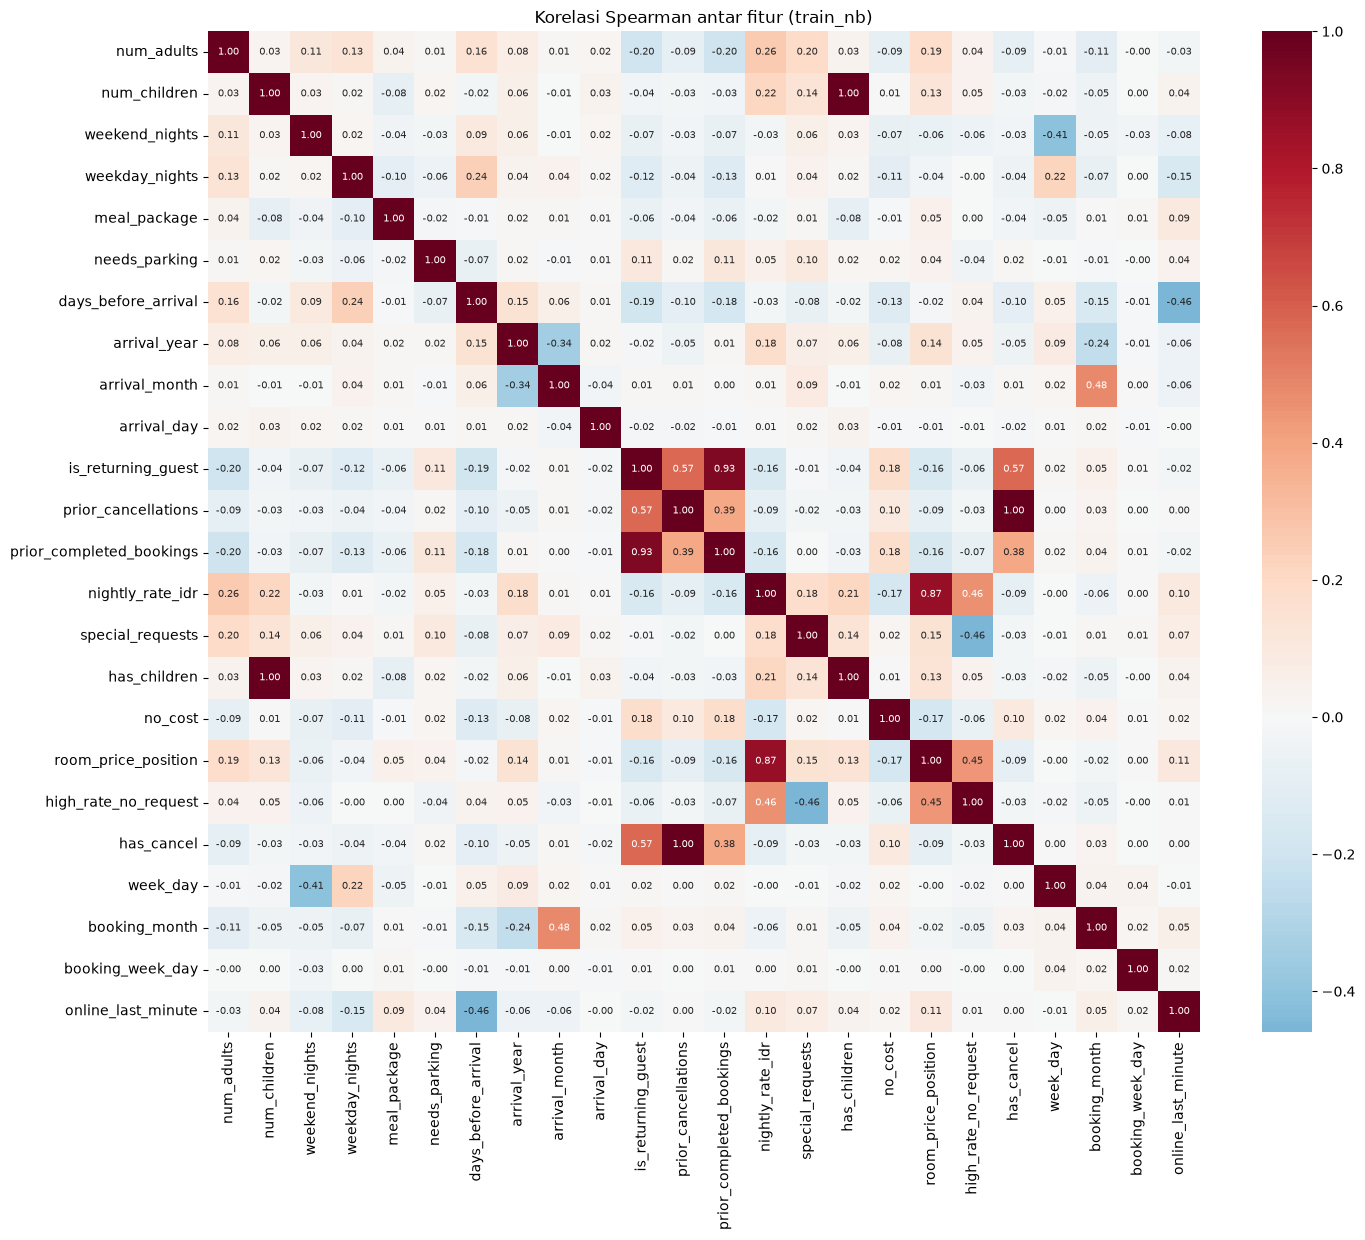

In [93]:
NOMINAL_COLS = ['room_category', 'booking_channel']
CORR_COLS = [c for c in FEATURES_NB if c not in NOMINAL_COLS]

corr = train_nb[CORR_COLS].corr(method='spearman')

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Korelasi Spearman antar fitur (train_nb)')
plt.show()

In [94]:
CORR_THRESHOLD = 0.8
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))  
strong_pairs = upper.stack().loc[lambda s: s >= CORR_THRESHOLD].sort_values(ascending=False)
strong_pairs

prior_cancellations  has_cancel                  0.999991
num_children         has_children                0.999299
is_returning_guest   prior_completed_bookings    0.933977
nightly_rate_idr     room_price_position         0.866081
dtype: float64

In [95]:
mi = fs_scores.set_index('feature')['mutual_info']

drop_redundant = set()
for (a, b), r in strong_pairs.items():
    if a in drop_redundant or b in drop_redundant:
        continue
    drop_redundant.add(a if mi[a] < mi[b] else b)

drop_insignificant = set(fs_scores.loc[fs_scores['p_value'] > 0.05, 'feature'])

FEATURES_NB_SELECTED = [c for c in FEATURES_NB if c not in drop_redundant | drop_insignificant]

print('Redundan        :', sorted(drop_redundant))
print('Tidak signifikan:', sorted(drop_insignificant))
print(f'Terpilih: {len(FEATURES_NB_SELECTED)} dari {len(FEATURES_NB)} fitur')

Redundan        : ['has_cancel', 'has_children', 'nightly_rate_idr', 'prior_completed_bookings']
Tidak signifikan: ['booking_week_day']
Terpilih: 21 dari 26 fitur


**Insights**

- Setelah discretization, seluruh fitur dan target `is_canceled` bersifat kategorikal. Untuk kombinasi ini, teknik statistik yang sesuai adalah Chi-Squared test pada contingency table dan Mutual Information.
- Fitur dengan korelasi Spearman ≥ 0,8 membawa informasi yang hampir sama, jadi salah satu dibuang. 
- Menggunakan Spearman karena data berupa nilai diskrit, jadi spearman mengukur hubungan berdasarkan peringkat tanpa mengasumsikan hubungan linear. 

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

Jumlah fitur versi A: 92


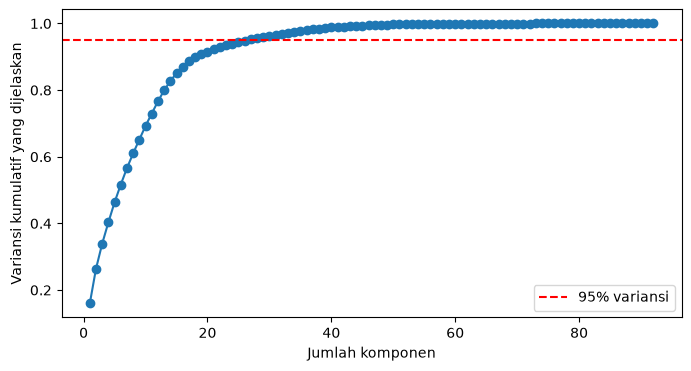

Komponen untuk 95% variansi: 27 dari 92 fitur


In [96]:
FEATURES_A = [c for c in train_a.columns if c not in (ID_COL, TARGET)]
print('Jumlah fitur versi A:', len(FEATURES_A))

pca_full = PCA(random_state=CFG.SEED).fit(train_a[FEATURES_A])
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% variansi')
plt.xlabel('Jumlah komponen')
plt.ylabel('Variansi kumulatif yang dijelaskan')
plt.legend()
plt.show()

n_components = int(np.argmax(cum_var >= 0.95) + 1)
print(f'Komponen untuk 95% variansi: {n_components} dari {len(FEATURES_A)} fitur')

In [97]:
pca = PCA(n_components=n_components, random_state=CFG.SEED).fit(train_a[FEATURES_A])

def apply_pca(df):
    pcs = pca.transform(df[FEATURES_A])
    out = pd.DataFrame(pcs, columns=[f'PC{i+1}' for i in range(n_components)], index=df.index)
    out.insert(0, ID_COL, df[ID_COL].values)
    if TARGET in df:
        out[TARGET] = df[TARGET].values
    return out

train_pca, val_pca, test_pca = apply_pca(train_a), apply_pca(val_a), apply_pca(test_a)
print(train_pca.shape, val_pca.shape, test_pca.shape)

(21858, 29) (5475, 29) (6844, 28)


**Insights**

- Beberapa fitur saling berkorelasi (misalnya `prior_cancellations` dengan `has_cancel`, `num_children` dengan `has_children`, atau `nightly_rate_idr` dengan `room_price_position`). PCA merangkumnya menjadi komponen yang lebih sedikit dan tidak saling berkorelasi, yang dapat mempercepat dan menstabilkan model berbasis jarak seperti KNN.
- Jumlah komponen dipilih sebagai jumlah minimum yang mempertahankan 95% variansi. Sebanyak 16 dari 36 fitur sudah mencapai ambang tersebut, sedangkan 20 komponen sisanya hanya menambah kurang dari 5% variansi, sehingga dimensi berkurang sekitar 56% tanpa kehilangan banyak informasi.
- PCA mencari arah dengan variansi terbesar, sehingga tanpa scaling, fitur dengan rentang besar akan mendominasi komponen.


## Class Balance

This part covers the proportion of each class in the training data.

In [98]:
print(train_set[TARGET].value_counts())
print(train_set[TARGET].value_counts(normalize=True).round(3))

is_canceled
0    14696
1     7162
Name: count, dtype: int64
is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


In [99]:
def random_oversample(df, seed=CFG.SEED):
    counts = df[TARGET].value_counts()
    majority, minority = counts.idxmax(), counts.idxmin()
    n_extra = counts[majority] - counts[minority]
    extra = df[df[TARGET] == minority].sample(n=n_extra, replace=True, random_state=seed)
    return pd.concat([df, extra]).sample(frac=1, random_state=seed).reset_index(drop=True)

train_nb_bal  = random_oversample(train_nb)
train_a_bal   = random_oversample(train_a)
train_pca_bal = random_oversample(train_pca)

for name, df in [('Data awal:', train_nb), ('Data akhir:', train_nb_bal)]:
    print(f'{name:12s}', df.shape, df[TARGET].value_counts(normalize=True).round(3).to_dict())

Data awal:   (21858, 28) {0: 0.672, 1: 0.328}
Data akhir:  (29392, 28) {1: 0.5, 0: 0.5}


**Insights**

- Distribusi target pada `train_set` adalah 67% tidak batal (14.696 baris) dan 33% batal (7.162 baris).
- Menggunakan random oversampling supaya baris kelas minoritas disalin secara acak hingga jumlahnya sama dengan kelas mayoritas.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [100]:
FEATURES_PCA = [c for c in train_pca.columns if c.startswith('PC')]

def to_xy(df, features, dtype=float):
    X = df[features].to_numpy(dtype=dtype)
    y = df[TARGET].to_numpy(dtype=int) if TARGET in df else None
    return X, y

# Naive Bayes
X_train_nb, y_train_nb         = to_xy(train_nb, FEATURES_NB_SELECTED, int)
X_train_nb_bal, y_train_nb_bal = to_xy(train_nb_bal, FEATURES_NB_SELECTED, int)
X_val_nb, y_val                = to_xy(val_nb, FEATURES_NB_SELECTED, int)
X_test_nb, _                   = to_xy(test_nb, FEATURES_NB_SELECTED, int)

# Versi A: Semua fitur + yg dibuat sendiri. Bisa dipake buat logres, KNN, SVM, DTL, 
X_train_a, y_train_a           = to_xy(train_a, FEATURES_A)
X_train_a_bal, y_train_a_bal   = to_xy(train_a_bal, FEATURES_A)
X_val_a, _                     = to_xy(val_a, FEATURES_A)
X_test_a, _                    = to_xy(test_a, FEATURES_A)

X_train_pca, y_train_pca         = to_xy(train_pca, FEATURES_PCA)
X_train_pca_bal, y_train_pca_bal = to_xy(train_pca_bal, FEATURES_PCA)
X_val_pca, _                     = to_xy(val_pca, FEATURES_PCA)
X_test_pca, _                    = to_xy(test_pca, FEATURES_PCA)

test_ids = test_set[ID_COL].to_numpy()

In [101]:
checks = {
    'NB':  (X_train_nb, X_train_nb_bal, X_val_nb, X_test_nb),
    'A':   (X_train_a, X_train_a_bal, X_val_a, X_test_a),
    'PCA': (X_train_pca, X_train_pca_bal, X_val_pca, X_test_pca),
}
for name, arrs in checks.items():
    print(f'{name:4s}', [a.shape for a in arrs], '| NaN:', sum(np.isnan(a.astype(float)).sum() for a in arrs))

assert len(y_val) == len(X_val_nb) == len(X_val_a) == len(X_val_pca)
assert len(test_ids) == len(X_test_nb) == len(sample_sub)

NB   [(21858, 21), (29392, 21), (5475, 21), (6844, 21)] | NaN: 0
A    [(21858, 92), (29392, 92), (5475, 92), (6844, 92)] | NaN: 0
PCA  [(21858, 27), (29392, 27), (5475, 27), (6844, 27)] | NaN: 0


**Insights**

- Setiap model membutuhkan representasi yang berbeda. Naive Bayes menggunakan fitur diskret hasil seleksi (21 fitur), sedangkan KNN, Logistic Regression, dan SVM menggunakan fitur ter-scale dan one-hot (36 fitur) atau hasil PCA (16 komponen).


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

Fungsi berikut menggabungkan langkah Data Preparation untuk fitur A. Fungsi cleaning, scaling, dan encoding yang sama dipake kembali pada data mentah setiap fold dan pelatihan final.

In [102]:
def prepare_features_a(raw_fit, raw_eval):
    train, other = clean_reservations(raw_fit, raw_eval)
    train, other = transform_features_a(train, other)
    features = train.columns.drop([ID_COL, TARGET])
    X_train, y_train = to_xy(train, features)
    X_other, _ = to_xy(other, features)
    return X_train, y_train, X_other

In [103]:
def prepare_features_nb(raw_fit, raw_eval, features=None):
    train, other = clean_reservations(raw_fit, raw_eval)

    room_rates = train.groupby('room_category')['nightly_rate_idr'].median()
    rate_median = train['nightly_rate_idr'].median()
    train = construct_attributes(train, room_rates, rate_median)
    other = construct_attributes(other, room_rates, rate_median)

    counts = train['room_category'].value_counts()
    rare = counts[counts < MIN_COUNT].index
    train, other = merging(train.copy(), rare), merging(other.copy(), rare)

    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(train[CATEGORICAL])
    def label_encode(df):
        df = df.drop(columns=NB_EXCLUDED, errors='ignore').copy()
        df[CATEGORICAL] = encoder.transform(df[CATEGORICAL]).astype(int)
        return df
    train, other = label_encode(train), label_encode(other)

    bins = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile').fit(train[BIN_COLS])
    caps = count_caps(train)
    train = apply_discretization(train, bins, caps)
    other = apply_discretization(other, bins, caps)

    features = FEATURES_NB_SELECTED if features is None else features
    features = [c for c in features if c in train.columns]
    X_train, y_train = to_xy(train, features, int)
    X_other, _ = to_xy(other, features, int)
    return X_train, y_train, X_other

In [104]:
X_fit_check, y_fit_check, X_val_check = prepare_features_nb(train_raw, val_raw)
print('Train sama:', np.array_equal(X_fit_check, X_train_nb) and np.array_equal(y_fit_check, y_train_nb))
print('Val sama  :', np.array_equal(X_val_check, X_val_nb))

Train sama: True
Val sama  : True


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [105]:
# Write your code here

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [106]:
# Write your code here

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.


Eksperimen memakai fitur A dan ambang 0,5. Ketiga penalti ikut dievaluasi pada holdout dan K-Fold.


Pada eksperimen awal ini, semua penalti memakai lambda = 0,01. Pemilihan konfigurasi berdasarkan K-Fold dilakukan pada bagian Improvements.

In [107]:
from algorithm.log_regression import LogisticRegression

lr_options = dict(learning_rate=0.001, max_iteration=100, random=CFG.SEED)
lr_models = {}
lr_predictions = {}
lr_results = []

for penalty in ('l1', 'l2', 'elasticnet'):
    model = LogisticRegression(penalty=penalty, lmda=0.01, **lr_options)
    model.fit(X_train_a, y_train_a)
    predictions = model.predict(X_val_a)
    lr_models[penalty] = model
    lr_predictions[penalty] = predictions
    lr_results.append({'Penalti': penalty, 'Macro F1 validasi': f1_score(y_val, predictions, zero_division=0, average='macro')})

pd.DataFrame(lr_results).set_index('Penalti').round(4)

,Macro F1 validasi
Penalti,
l1,0.7577
l2,0.7730
elasticnet,0.7630


## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [108]:
from algorithm.SVM import Svm

def prepare_features_pca(raw_fit, raw_eval):
    train, other = clean_reservations(raw_fit, raw_eval)
    train, other = transform_features_a(train, other)
    features = train.columns.drop([ID_COL, TARGET])
    X_fit, y_fit = to_xy(train, features)
    X_eval, _ = to_xy(other, features)
    X_fit = pca.transform(X_fit)
    X_eval = pca.transform(X_eval)
    return X_fit, y_fit, X_eval

X_svm_fit, y_svm_fit = X_train_pca, y_train_pca
X_svm_val, y_svm_val = X_val_pca, y_val

svm_models = {}
svm_predictions = {}
svm_results = []
for name, kernel, extra in (
    ('Linear', 'linear', {}),
    ('Polynomial', 'polynomial', {'degree': 2, 'coef0': 0.7}),
    ('Gaussian RBF', 'rbf', {'gamma': 0.05}),
):
    model = Svm(kernel=kernel, C=1.0, n_iters=250, learning_rate=1e-3, tolerance=1e-5, **extra)
    model.fit(X_svm_fit, y_svm_fit)
    pred = model.predict(X_svm_val)
    svm_models[name] = model
    svm_predictions[name] = pred
    svm_results.append({
        'Kernel': name,
        'Support vector': int(np.sum(model.alpha > 1e-5)),
        'Macro F1 validasi': f1_score(y_svm_val, pred, average='macro'),
    })

pd.DataFrame(svm_results).set_index('Kernel').round(4)

MemoryError: Unable to allocate 3.56 GiB for an array with shape (21858, 21858) and data type float64

### Bidang Pemisah, Margin, dan Support Vector

Visualisasi memakai PCA 2 komponen dan sampel berlapis agar interpretasi kernel dapat dilihat dalam bidang 2D. Garis kontur 0 adalah bidang pemisah; kontur -1 dan +1 menandai batas margin.

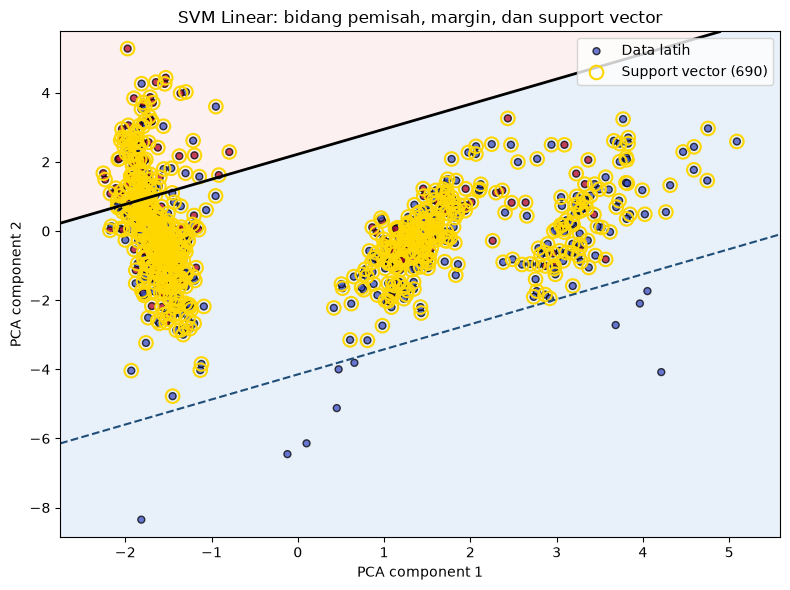

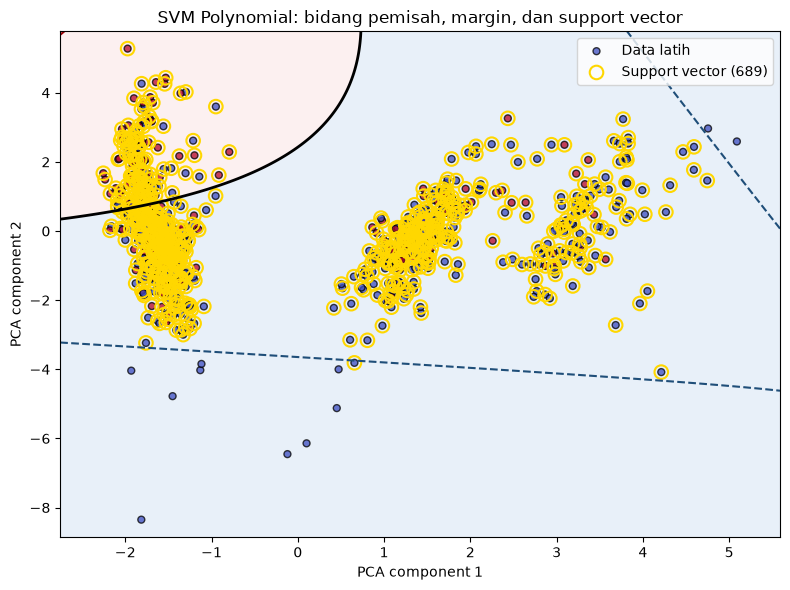

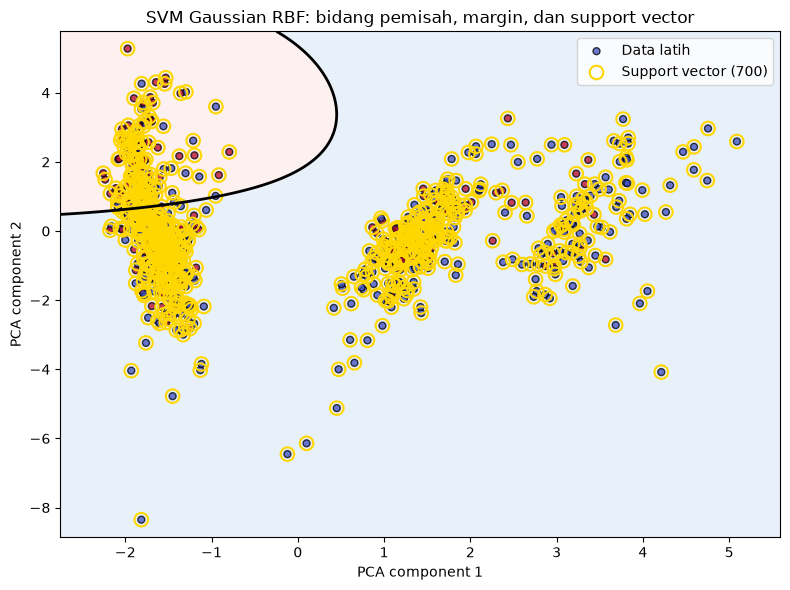

In [ ]:
rng_vis = np.random.default_rng(CFG.SEED)
vis_indices = []
for label in np.unique(y_svm_fit):
    cls_indices = np.flatnonzero(y_svm_fit == label)
    take = min(700 // len(np.unique(y_svm_fit)), len(cls_indices))
    vis_indices.extend(rng_vis.choice(cls_indices, size=take, replace=False).tolist())
X_vis, y_vis = X_svm_fit[np.asarray(vis_indices)], y_svm_fit[np.asarray(vis_indices)]
pca2 = PCA(n_components=2, random_state=CFG.SEED).fit(X_vis)
X_vis = pca2.transform(X_vis)

plot_specs = [
    ('Linear', 'linear_decision_boundary.png', {}),
    ('Polynomial', 'polynomial_decision_boundary.png', {'degree': 2, 'coef0': 0.7}),
    ('Gaussian RBF', 'gaussian_rbf_decision_boundary.png', {'gamma': 0.05}),
]

for title, filename, options in plot_specs:
    kernel = 'linear' if title == 'Linear' else ('polynomial' if title == 'Polynomial' else 'rbf')
    vis_model = Svm(kernel=kernel, n_iters=250, learning_rate=1e-3, tolerance=1e-5, **options).fit(X_vis, y_vis)

    x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
    y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    zz = vis_model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, zz, levels=[-np.inf, 0, np.inf], alpha=0.20, colors=['#8db4e2', '#f2b6b6'])
    plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors=['#1f4e79', 'black', '#9c0006'],
                linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])
    plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, cmap='coolwarm',
                edgecolors='k', s=25, alpha=0.75, label='Data latih')
    plt.scatter(vis_model.support_vectors[:, 0], vis_model.support_vectors[:, 1],
                s=95, facecolors='none', edgecolors='gold', linewidths=1.5,
                label=f'Support vector ({len(vis_model.support_vectors)})')
    plt.title(f'SVM {title}: bidang pemisah, margin, dan support vector')
    plt.xlabel('PCA component 1')
    plt.ylabel('PCA component 2')
    plt.legend(loc='best')
    plt.tight_layout()
    (CFG.OUTPUT_DIR / 'images').mkdir(parents=True, exist_ok=True)
    plt.savefig(CFG.OUTPUT_DIR / 'images' / filename, dpi=150)
    plt.show()

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [ ]:
from algorithm.naive import NaiveBayes

nb_models = {}
nb_predictions = {}
nb_results = []

for name, (X_tr, y_tr) in {'asli': (X_train_nb, y_train_nb), 'oversampled': (X_train_nb_bal, y_train_nb_bal)}.items():
    model = NaiveBayes(alpha=1.0).fit(X_tr, y_tr)
    predictions = model.predict(X_val_nb)
    nb_models[name] = model
    nb_predictions[name] = predictions
    nb_results.append({'Data latih': name, 'Macro F1 validasi': f1_score(y_val, predictions, average='macro')})

pd.DataFrame(nb_results).set_index('Data latih').round(4)

,Macro F1 validasi
Data latih,
asli,0.7522
oversampled,0.7137


In [ ]:
nb_model = nb_models['asli']
y_pred_nb = nb_predictions['asli']

print(classification_report(y_val, y_pred_nb, digits=4))
print(confusion_matrix(y_val, y_pred_nb))

              precision    recall  f1-score   support

           0     0.8363    0.8408    0.8385      3681
           1     0.6697    0.6622    0.6659      1794

    accuracy                         0.7823      5475
   macro avg     0.7530    0.7515    0.7522      5475
weighted avg     0.7817    0.7823    0.7820      5475

[[3095  586]
 [ 606 1188]]


## Model Evaluation

### Holdout

Bagian ini mengumpulkan model beserta prediksi validasinya, lalu menghitung accuracy, precision, recall, dan F1 untuk kelas batal. Model yang masih berisi None akan dilewati.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

models = {
    'KNN': None,            # GANTIFUNGSIMODELKNN
    'Decision Tree': None,  # GANTIFUNGSIMODELDTL
    'Logistic Regression (L1)': (lr_models['l1'], prepare_features_a, lr_predictions['l1']),
    'Logistic Regression (L2)': (lr_models['l2'], prepare_features_a, lr_predictions['l2']),
    'Logistic Regression (Elastic Net)': (lr_models['elasticnet'], prepare_features_a, lr_predictions['elasticnet']),
    'SVM (Linear)': (svm_models['Linear'], prepare_features_pca, svm_predictions['Linear']),
    'SVM (Polynomial)': (svm_models['Polynomial'], prepare_features_pca, svm_predictions['Polynomial']),
    'SVM (Gaussian RBF)': (svm_models['Gaussian RBF'], prepare_features_pca, svm_predictions['Gaussian RBF']),
    'Naive Bayes': (nb_model, prepare_features_nb, y_pred_nb),   
}
active_models = {name: entry for name, entry in models.items() if entry is not None}

In [ ]:
holdout = {}
for name in active_models:
    model, prepare, pred = active_models[name]
    holdout[name] = {
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0, average='macro'),
        'Recall': recall_score(y_val, pred, zero_division=0, average='macro'),
        'Macro F1': f1_score(y_val, pred, zero_division=0, average='macro'),
    }
holdout_scores = pd.DataFrame(holdout).T
holdout_scores.round(4)

,Accuracy,Precision,Recall,Macro F1
Logistic Regression (L1),0.7965,0.7751,0.7474,0.7577
Logistic Regression (L2),0.8069,0.7856,0.7644,0.7730
Logistic Regression (Elastic Net),0.7998,0.7781,0.7535,0.7630
Naive Bayes,0.7823,0.7530,0.7515,0.7522


### Precision, recall, dan F1 per model

Grafik berikut membandingkan ketiga skor pada data holdout untuk setiap model yang sudah terhubung.

In [ ]:
holdout_scores[['Precision', 'Recall', 'Macro F1']].T.plot.bar(
    rot=0, ylim=(0, 1), ylabel='Skor holdout', colormap='tab10',
)
plt.tight_layout()
plt.show()

NameError: name 'holdout_scores' is not defined

Hasil holdout -> Pada ambang 0,5, precision L2 mencapai 73,0% dan recall 59,4%. Artinya, dari setiap 100 pembatalan aktual, sekitar 41 masih terlewat. Hal ini menjadi alasan untuk menguji ambang lebih rendah pada bagian Improvements.

### K-Fold Cross Validation

Kode berikut membagi data latih menjadi tiga fold secara stratified. Pada setiap fold, preprocessing dan model dilatih ulang menggunakan bagian latih fold tersebut. Tabel hasil menampilkan F1 holdout, rata-rata F1 K-Fold, dan simpangan bakunya.

In [ ]:
from copy import deepcopy
from sklearn.model_selection import StratifiedKFold

folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
splits = list(folds.split(train_raw, train_raw[TARGET]))

def kfold_scores(model, prepare):
    scores = []
    for fit_idx, eval_idx in splits:
        fold_eval = train_raw.iloc[eval_idx]
        X_fit, y_fit, X_eval = prepare(train_raw.iloc[fit_idx], fold_eval)
        fold_model = deepcopy(model)
        fold_model.fit(X_fit, y_fit)
        pred = fold_model.predict(X_eval)
        score = f1_score(fold_eval[TARGET], pred, zero_division=0, average='macro')
        scores.append(score)
    return scores

fold_scores = {}
for name in active_models:
    model, prepare, pred = active_models[name]
    fold_scores[name] = kfold_scores(model, prepare)

kfold = pd.DataFrame(fold_scores).agg(['mean', 'std']).T

comparison = holdout_scores[['Macro F1']].join(kfold)
comparison.columns = ['Macro F1 holdout', 'Macro F1 K-Fold', 'Std K-Fold']
comparison.round(4)

## Improvements (Optional)

### Logistic Regression Improvement

Kode berikut mencoba beberapa kombinasi penalti, lambda, dan ambang prediksi pada fold yang sama. Rata-rata F1 setiap kombinasi ditampilkan dalam tabel untuk membandingkan pengaruh parameternya.

In [ ]:
thresholds = np.round(np.arange(0.25, 0.651, 0.025), 3)
lambdas = [0.001, 0.01]
cv_rows = []

for fit_idx, eval_idx in splits:
    fold_train = train_raw.iloc[fit_idx]
    fold_eval = train_raw.iloc[eval_idx]
    X_fit, y_fit, X_eval = prepare_features_a(fold_train, fold_eval)
    y_eval = fold_eval[TARGET]

    for penalty in lr_models:
        for lmda in lambdas:
            fold_lr = LogisticRegression(penalty=penalty, lmda=lmda, **lr_options)
            fold_lr.fit(X_fit, y_fit)
            prob = fold_lr.probability(X_eval)

            for threshold in thresholds:
                pred = prob >= threshold
                score = f1_score(y_eval, pred, zero_division=0, average='macro')
                cv_rows.append({
                    'Penalti': penalty,
                    'Lambda': lmda,
                    'Ambang': threshold,
                    'Macro F1': score,
                })
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby(['Penalti', 'Lambda', 'Ambang'])['Macro F1'].mean()
cv_table = cv_summary.unstack('Ambang')
cv_table.round(4)

Ambang              0.250   0.275   0.300   0.325   0.350   0.375   0.400  \
Penalti    Lambda                                                           
elasticnet 0.001   0.7474  0.7543  0.7618  0.7657  0.7691  0.7742  0.7778   
           0.010   0.7297  0.7415  0.7501  0.7580  0.7659  0.7703  0.7716   
l1         0.001   0.7470  0.7539  0.7619  0.7648  0.7685  0.7734  0.7773   
           0.010   0.7237  0.7341  0.7432  0.7529  0.7607  0.7681  0.7709   
l2         0.001   0.7480  0.7556  0.7626  0.7666  0.7699  0.7736  0.7781   
           0.010   0.7379  0.7481  0.7578  0.7620  0.7681  0.7720  0.7745   

Ambang              0.425   0.450   0.475   0.500   0.525   0.550   0.575  \
Penalti    Lambda                                                           
elasticnet 0.001   0.7795  0.7815  0.7821  0.7796  0.7751  0.7694  0.7616   
           0.010   0.7747  0.7742  0.7703  0.7650  0.7604  0.7530  0.7438   
l1         0.001   0.7788  0.7816  0.7814  0.7787  0.7750  0.7684  0.7613   
           0.010   0.7725  0.7708  0.7662  0.7602  0.7542  0.7436  0.7349   
l2         0.001   0.7797  0.7816  0.7828  0.7801  0.7759  0.7687  0.7621   
           0.010   0.7762  0.7780  0.7764  0.7737  0.7672  0.7608  0.7503   

Ambang              0.600   0.625   0.650  
Penalti    Lambda                          
elasticnet 0.001   0.7532  0.7445  0.7351  
           0.010   0.7315  0.7155  0.6989  
l1         0.001   0.7527  0.7433  0.7332  
           0.010   0.7202  0.7025  0.6912  
l2         0.001   0.7553  0.7454  0.7351  
           0.010   0.7406  0.7297  0.7161

### Naive Bayes Improvement

Kode berikut mencoba beberapa nilai Laplace smoothing (`alpha`) dan ambang prediksi pada fold yang sama dengan logistic regression. Pada setiap fold, pipeline Naive Bayes dilatih ulang menggunakan bagian latih fold tersebut.

In [ ]:
nb_alphas = [0.1, 0.5, 1.0, 2.0, 5.0]
nb_thresholds = np.round(np.arange(0.30, 0.651, 0.025), 3)
nb_cv_rows = []

for fit_idx, eval_idx in splits:
    fold_eval = train_raw.iloc[eval_idx]
    X_fit, y_fit, X_eval = prepare_features_nb(train_raw.iloc[fit_idx], fold_eval)
    y_eval = fold_eval[TARGET]

    for alpha in nb_alphas:
        prob = NaiveBayes(alpha=alpha).fit(X_fit, y_fit).predict_proba(X_eval)[:, 1]
        for threshold in nb_thresholds:
            pred = prob >= threshold
            nb_cv_rows.append({'Alpha': alpha, 'Ambang': threshold, 'Macro F1': f1_score(y_eval, pred, zero_division=0, average='macro')})

nb_cv_summary = pd.DataFrame(nb_cv_rows).groupby(['Alpha', 'Ambang'])['Macro F1'].mean()
nb_cv_summary.unstack('Ambang').round(4)

Ambang,0.300,0.325,0.350,0.375,0.400,0.425,0.450,0.475,0.500,0.525,0.550,0.575,0.600,0.625,0.650
Alpha,,,,,,,,,,,,,,,
0.1,0.7105,0.7173,0.7234,0.7281,0.7316,0.7361,0.7404,0.7438,0.7468,0.7488,0.7488,0.7498,0.7514,0.7489,0.7460
0.5,0.7141,0.7212,0.7268,0.7302,0.7350,0.7389,0.7433,0.7467,0.7484,0.7493,0.7496,0.7510,0.7499,0.7466,0.7425
1.0,0.7188,0.7249,0.7294,0.7342,0.7372,0.7422,0.7461,0.7482,0.7491,0.7495,0.7515,0.7502,0.7475,0.7442,0.7392
2.0,0.7241,0.7289,0.7337,0.7370,0.7423,0.7461,0.7483,0.7489,0.7495,0.7514,0.7503,0.7475,0.7442,0.7394,0.7315
5.0,0.7304,0.7351,0.7400,0.7443,0.7472,0.7485,0.7489,0.7498,0.7513,0.7489,0.7463,0.7416,0.7341,0.7254,0.7169


### SVM Improvement dan Tuning

Grid kecil mencoba parameter kernel pada 3-fold. Setiap fold memakai pipeline yang sama: preprocessing pada bagian latih, transformasi pada bagian evaluasi, pelatihan SVM, lalu prediksi. Parameter terpilih dipakai untuk model holdout.

In [ ]:
svm_grid = {
    'Linear': [{'C': C} for C in (0.1, 1.0)],
    'Polynomial': [{'C': C, 'degree': degree, 'coef0': 1.0, 'gamma': gamma}
                   for C in (1.0,) for degree in (2, 3) for gamma in (0.1,)],
    'Gaussian RBF': [{'C': C, 'gamma': gamma} for C in (1.0,) for gamma in (0.01, 0.1)],
}

svm_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=CFG.SEED)
svm_splits = list(svm_folds.split(X_train_pca, y_train_pca))

svm_tuning_rows = []
for kernel_name, options_list in svm_grid.items():
    kernel = {'Linear': 'linear', 'Polynomial': 'polynomial', 'Gaussian RBF': 'rbf'}[kernel_name]
    for options in options_list:
        fold_scores = []
        for fit_idx, eval_idx in svm_splits:
            X_fit, y_fit = X_train_pca[fit_idx], y_train_pca[fit_idx]
            model = Svm(kernel=kernel, n_iters=80, learning_rate=1e-3, tolerance=1e-4, **options)
            model.fit(X_fit, y_fit)
            pred = model.predict(X_train_pca[eval_idx])
            fold_scores.append(f1_score(y_train_pca[eval_idx], pred, average='macro'))
        svm_tuning_rows.append({
            'Kernel': kernel_name,
            **options,
            'Macro F1 K-Fold': np.mean(fold_scores),
            'Std': np.std(fold_scores),
        })

svm_tuning = pd.DataFrame(svm_tuning_rows).sort_values('Macro F1 K-Fold', ascending=False)
svm_tuning.round(4)

,Kernel,C,Macro F1 K-Fold,Std,degree,coef0,gamma
4,Gaussian RBF,1.0,0.7418,0.0059,NaN,NaN,0.01
2,Polynomial,1.0,0.7131,0.0621,2.0,1.0,0.10
5,Gaussian RBF,1.0,0.7084,0.0088,NaN,NaN,0.10
3,Polynomial,1.0,0.5736,0.0609,3.0,1.0,0.10
0,Linear,0.1,0.3176,0.0013,NaN,NaN,NaN
1,Linear,1.0,0.3147,0.0008,NaN,NaN,NaN


In [ ]:
nb_feature_sets = {'Terpilih': FEATURES_NB_SELECTED, 'Semua': FEATURES_NB}
nb_feature_rows = []

for label, feats in nb_feature_sets.items():
    scores = []
    for fit_idx, eval_idx in splits:
        fold_eval = train_raw.iloc[eval_idx]
        X_fit, y_fit, X_eval = prepare_features_nb(train_raw.iloc[fit_idx], fold_eval, features=feats)
        pred = NaiveBayes(alpha=1.0).fit(X_fit, y_fit).predict(X_eval)
        scores.append(f1_score(fold_eval[TARGET], pred, zero_division=0, average='macro'))
    nb_feature_rows.append({'Set fitur': label, 'Jumlah fitur': len(feats), 'Macro F1 K-Fold': np.mean(scores)})

pd.DataFrame(nb_feature_rows).set_index('Set fitur').round(4)

,Jumlah fitur,Macro F1 K-Fold
Set fitur,,
Terpilih,21,0.7491
Semua,26,0.7403


In [ ]:
nb_best_alpha, nb_best_threshold = nb_cv_summary.idxmax()
tuned_nb = NaiveBayes(alpha=nb_best_alpha).fit(X_train_nb, y_train_nb)
tuned_pred_nb = tuned_nb.predict(X_val_nb, threshold=nb_best_threshold)

pd.DataFrame([{
    'Alpha': nb_best_alpha,
    'Ambang': nb_best_threshold,
    'Macro F1 K-Fold': nb_cv_summary.max(),
    'Macro F1 holdout (default)': f1_score(y_val, y_pred_nb, average='macro'),
    'Macro F1 holdout (tuning)': f1_score(y_val, tuned_pred_nb, average='macro'),
}], index=['Naive Bayes']).round(4)

,Alpha,Ambang,Macro F1 K-Fold,Macro F1 holdout (default),Macro F1 holdout (tuning)
Naive Bayes,1.0,0.55,0.7515,0.7522,0.7526


In [ ]:
best_svm_row = svm_tuning.iloc[0]
best_svm_kernel = {'Linear': 'linear', 'Polynomial': 'polynomial', 'Gaussian RBF': 'rbf'}[best_svm_row['Kernel']]
best_svm_options = {
    'C': float(best_svm_row['C']),
    'n_iters': 250,
    'learning_rate': 1e-3,
    'tolerance': 1e-5,
}
for key in ('degree', 'coef0', 'gamma'):
    if key in svm_tuning.columns and pd.notna(best_svm_row.get(key)):
        best_svm_options[key] = int(best_svm_row[key]) if key == 'degree' else float(best_svm_row[key])

tuned_svm = Svm(kernel=best_svm_kernel, **best_svm_options).fit(X_svm_fit, y_svm_fit)
tuned_pred_svm = tuned_svm.predict(X_svm_val)
print('SVM terbaik:', best_svm_row['Kernel'], best_svm_options)
print('Macro F1 holdout:', round(f1_score(y_svm_val, tuned_pred_svm, average='macro'), 4))

SVM terbaik: Gaussian RBF {'C': 1.0, 'n_iters': 250, 'learning_rate': 0.001, 'tolerance': 1e-05, 'gamma': 0.01}
Macro F1 holdout: 0.7593


### Perbandingan SVM dengan scikit-learn

Implementasi dari awal dibandingkan dengan `SVC` pada konfigurasi kernel dan parameter tuning yang sama. Perbandingan memakai sampel holdout yang sama untuk mengukur kesesuaian prediksi.

In [ ]:
from sklearn.svm import SVC

sklearn_options = {
    'C': float(best_svm_row['C']),
    'kernel': best_svm_kernel,
    'random_state': CFG.SEED,
}
if best_svm_row['Kernel'] == 'Polynomial':
    sklearn_options.update({
        'degree': int(best_svm_row['degree']),
        'coef0': float(best_svm_row['coef0']),
        'gamma': float(best_svm_row['gamma']),
    })
elif best_svm_row['Kernel'] == 'Gaussian RBF':
    sklearn_options['gamma'] = float(best_svm_row['gamma'])

sklearn_svm = SVC(**sklearn_options).fit(X_svm_fit, y_svm_fit)
sklearn_pred_svm = sklearn_svm.predict(X_svm_val)

pd.DataFrame([{
    'Kernel': best_svm_row['Kernel'],
    'Macro F1 kelompok': f1_score(y_svm_val, tuned_pred_svm, average='macro'),
    'Macro F1 scikit-learn': f1_score(y_svm_val, sklearn_pred_svm, average='macro'),
    'Prediksi identik': np.array_equal(tuned_pred_svm, sklearn_pred_svm),
}], index=['SVM']).round(4)

,Kernel,Macro F1 kelompok,Macro F1 scikit-learn,Prediksi identik
SVM,Gaussian RBF,0.7593,0.7616,False


### Evaluasi Hasil Tuning

Kode berikut mengambil kombinasi dengan rata-rata F1 tertinggi untuk setiap penalti, melatih ulang modelnya, lalu menghitung F1 pada holdout.

In [ ]:
tuned_lr_models = {}
tuned_lr_thresholds = {}
lr_tuning_rows = []

for penalty in lr_models:
    penalty_scores = cv_summary.loc[penalty]
    lmda, threshold = penalty_scores.idxmax()
    model = LogisticRegression(penalty=penalty, lmda=lmda, **lr_options)
    model.fit(X_train_a, y_train_a)
    pred = model.predict(X_val_a, threshold=threshold)

    tuned_lr_models[penalty] = model
    tuned_lr_thresholds[penalty] = threshold
    lr_tuning_rows.append({
        'Penalti': penalty,
        'Lambda': lmda,
        'Ambang': threshold,
        'Macro F1 K-Fold': penalty_scores.max(),
        'Macro F1 holdout': f1_score(y_val, pred, zero_division=0, average='macro'),
    })

lr_tuning = pd.DataFrame(lr_tuning_rows).set_index('Penalti')
best_penalty = lr_tuning['Macro F1 K-Fold'].idxmax()
tuned_lr = tuned_lr_models[best_penalty]
best_threshold = tuned_lr_thresholds[best_penalty]
val_prob_lr = tuned_lr.probability(X_val_a)
tuned_pred_lr = tuned_lr.predict(X_val_a, threshold=best_threshold)
print('Penalti terpilih berdasarkan K-Fold:', best_penalty)
lr_tuning.round(4)

Penalti terpilih berdasarkan K-Fold: l2


,Lambda,Ambang,Macro F1 K-Fold,Macro F1 holdout
Penalti,,,,
l1,0.001,0.450,0.7816,0.7767
l2,0.001,0.475,0.7828,0.7814
elasticnet,0.001,0.475,0.7821,0.7800


**Hasil tuning L2:**

Kombinasi lamda = 0,001 dan ambang 0,35 memberi rata-rata F1 antar-fold sebesar 0,6966. Pada holdout, F1 naik dari 0,6548 menjadi 0,6858. Recall naik dari 59,4% menjadi 75,3%, sementara precision turun dari 73,0% menjadi 63,0%.


Setelah tuning ketiga penalti, rata-rata F1 K-Fold L1 adalah 0,6941, L2 sebesar 0,6966, dan Elastic Net sebesar 0,6954. L2 terpilih berdasarkan skor K-Fold tertinggi. Semua penalti memilih lambda 0,001 dan ambang 0,35 pada grid yang diuji.

**Hasil tuning Naive Bayes:**

Kombinasi terbaik adalah `alpha` = 1,0 dan ambang 0,55, dengan Macro F1 K-Fold 0,7515. Pada holdout, Macro F1 hanya berubah dari 0,7522 menjadi 0,7526, sehingga pengaturan default sudah mendekati optimal untuk model ini.

### Pemilihan Model Terbaik

Bagian ini mengumpulkan skor K-Fold model yang sudah dievaluasi dan memakai hasil tuning untuk logistic regression. Model dengan rata-rata F1 tertinggi dipilih sebagai best_model untuk membuat submission.

In [ ]:
tuned_models = {}
model_scores = kfold['mean'].copy()
model_predict_options = {}

for name in active_models:
    model, prepare, pred = active_models[name]
    tuned_models[name] = model
    model_predict_options[name] = {}

lr_names = {
    'l1': 'Logistic Regression (L1)',
    'l2': 'Logistic Regression (L2)',
    'elasticnet': 'Logistic Regression (Elastic Net)',
}
for penalty in lr_names:
    name = lr_names[penalty]
    tuned_models[name] = tuned_lr_models[penalty]
    model_scores[name] = lr_tuning.loc[penalty, 'Macro F1 K-Fold']
    model_predict_options[name] = {'threshold': tuned_lr_thresholds[penalty]}

# Hasil Naive Bayes
tuned_models['Naive Bayes'] = tuned_nb
model_scores['Naive Bayes'] = nb_cv_summary.max()
tuned_models['SVM'] = tuned_svm
active_models['SVM'] = (tuned_svm, prepare_features_pca, tuned_pred_svm)
model_scores['SVM'] = svm_tuning['Macro F1 K-Fold'].max()
model_predict_options['SVM'] = {}
model_predict_options['Naive Bayes'] = {'threshold': nb_best_threshold}
best_name = model_scores.idxmax()
best_model = tuned_models[best_name]
best_prepare = active_models[best_name][1]
predict_options = model_predict_options[best_name]
print('Model terpilih:', best_name)
model_scores.sort_values(ascending=False).round(4)

Model terpilih: Logistic Regression (L2)


Logistic Regression (L2)             0.7828
Logistic Regression (Elastic Net)    0.7821
Logistic Regression (L1)             0.7816
Naive Bayes                          0.7515
SVM                                  0.7418
Name: mean, dtype: float64

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

### Logistic Regression

Kode berikut melatih logistic regression scikit-learn dengan fitur dan ambang yang sama seperti model awal kelompok. Nilai C disesuaikan dengan kekuatan regularisasi implementasi kelompok. Tabel hasil membandingkan F1 kedua implementasi untuk setiap penalti.

In [ ]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

comparison = {}
for penalty, scratch in lr_models.items():
    options = {'l1_ratio': scratch.l1_ratio} if penalty == 'elasticnet' else {}
    reference = SklearnLogisticRegression(
        penalty=penalty, C=1 / (len(y_train_a) * scratch.lmda), solver='saga',
        max_iter=3000, random_state=CFG.SEED, **options,
    ).fit(X_train_a, y_train_a)
    comparison[penalty] = {
        'Macro F1 kelompok': f1_score(y_val, lr_predictions[penalty], average='macro'),
        'Macro F1 scikit-learn': f1_score(y_val, reference.predict(X_val_a), average='macro'),
    }

pd.DataFrame(comparison).T.round(4)

,Macro F1 kelompok,Macro F1 scikit-learn
l1,0.7577,0.7535
l2,0.7730,0.7733
elasticnet,0.7630,0.7618


**Perbandingan:**

L2 menghasilkan F1 tertinggi untuk kedua implementasi pada ambang 0,5. Selisih F1 antara model kelompok (0,6548) dan scikit-learn (0,6517) sekitar 0,003 pada split ini.

### Naive Bayes

Kode berikut melatih `CategoricalNB` scikit-learn dengan data, fitur, dan `alpha` yang sama seperti model kelompok, lalu membandingkan Macro F1, prediksi, dan probabilitasnya.

In [ ]:
sk_nb = CategoricalNB(alpha=1.0).fit(X_train_nb, y_train_nb)
y_pred_sk_nb = sk_nb.predict(X_val_nb)

print('Macro F1 kelompok     :', round(f1_score(y_val, y_pred_nb, average='macro'), 4))
print('Macro F1 scikit-learn :', round(f1_score(y_val, y_pred_sk_nb, average='macro'), 4))
print('Prediksi identik      :', np.array_equal(y_pred_nb, y_pred_sk_nb))
print('Selisih proba maksimum:', np.abs(nb_model.predict_proba(X_val_nb) - sk_nb.predict_proba(X_val_nb)).max())

Macro F1 kelompok     : 0.7522
Macro F1 scikit-learn : 0.7522
Prediksi identik      : True
Selisih proba maksimum: 5.218048215738236e-15


**Perbandingan:**

Implementasi kelompok dan `CategoricalNB` menghasilkan Macro F1 yang sama dan prediksi yang identik pada seluruh data validasi. Selisih probabilitas hanya berasal dari pembulatan floating point.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [ ]:
model_files = {
    'KNN': None,            # GANTI_NAMA_FILE_KNN
    'Decision Tree': None,  # GANTI_NAMA_FILE_DTL
    'Logistic Regression (L1)': 'lr_l1.npz',
    'Logistic Regression (L2)': 'lr_l2.npz',
    'Logistic Regression (Elastic Net)': 'lr_elasticnet.npz',
    'SVM': 'svm.npz',
    'Naive Bayes': 'naive_bayes.npz', 
}

loaded_models = {}
save_results = []

for name in tuned_models:
    filename = model_files[name]
    if filename is None:
        continue

    model = tuned_models[name]
    path = CFG.OUTPUT_DIR / 'models' / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    model.save(path)
    loaded_model = type(model).load(path)
    loaded_models[name] = loaded_model

    prepare = active_models[name][1]
    _, _, X_check = prepare(train_raw, val_raw)
    options = model_predict_options[name]
    original_pred = model.predict(X_check, **options)
    loaded_pred = loaded_model.predict(X_check, **options)
    save_results.append({
        'Model': name,
        'Berkas': filename,
        'Prediksi sama': np.array_equal(original_pred, loaded_pred),
    })

pd.DataFrame(save_results)

,Model,Berkas,Prediksi sama
0,Logistic Regression (L1),lr_l1.npz,True
1,Logistic Regression (L2),lr_l2.npz,True
2,Logistic Regression (Elastic Net),lr_elasticnet.npz,True
3,Naive Bayes,naive_bayes.npz,True
4,SVM,svm.npz,True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
if best_name == 'SVM':
    X_full, y_full, X_test = prepare_features_pca(train_df, test_df)
    final_model = deepcopy(best_model)
    final_model.fit(X_full, y_full)
    predictions = final_model.predict(X_test)
else:
    X_full, y_full, X_test = best_prepare(train_df, test_df)
    final_model = deepcopy(best_model)
    final_model.fit(X_full, y_full)
    predictions = final_model.predict(X_test, **predict_options)

submission = sample_sub[[ID_COL]].copy()
predictions = pd.Series(predictions, index=test_df[ID_COL])
submission[TARGET] = submission[ID_COL].map(predictions)
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print('Model final:', best_name)
submission.head()

Model final: Logistic Regression (L2)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

### Kesalahan pada data validasi

Confusion matrix berikut menunjukkan jumlah prediksi benar dan salah dari logistic regression hasil tuning. False positive (FP) berarti reservasi aktif diprediksi batal. False negative (FN) berarti pembatalan diprediksi tetap berlangsung.

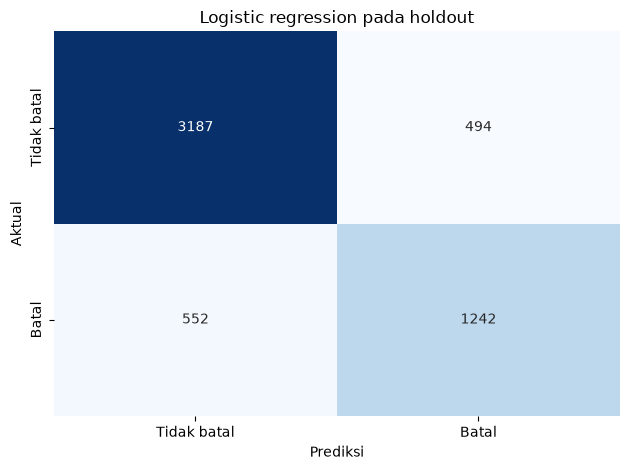

1046 dari 5475 prediksi salah (19.1%). FP = 494, FN = 552.


In [ ]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_val, tuned_pred_lr, labels=[0, 1])
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Tidak batal', 'Batal'], yticklabels=['Tidak batal', 'Batal'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Logistic regression pada holdout')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = matrix.ravel()
print(f'{fp + fn} dari {len(y_val)} prediksi salah ({(fp + fn) / len(y_val):.1%}). FP = {fp}, FN = {fn}.')

### Analisis kesalahan prediksi per reservasi dan kanal pemesanan

Kode berikut menggabungkan data validasi mentah, prediksi, dan probabilitas batal, lalu menampilkan hingga tiga baris untuk masing-masing FP dan FN. Nilai kosong dari data asal masih dapat terlihat pada tabel.

In [ ]:
val_results_lr = val_raw.copy()
val_results_lr['Prediksi'] = tuned_pred_lr
val_results_lr['P(batal)'] = val_prob_lr
val_results_lr['FP'] = (val_results_lr[TARGET] == 0) & (val_results_lr['Prediksi'] == 1)
val_results_lr['FN'] = (val_results_lr[TARGET] == 1) & (val_results_lr['Prediksi'] == 0)

errors_lr = val_results_lr.loc[val_results_lr['FP'] | val_results_lr['FN']].copy()
errors_lr['Kesalahan'] = 'FN'
errors_lr.loc[errors_lr['FP'], 'Kesalahan'] = 'FP'
columns = ['Kesalahan', ID_COL, 'booking_channel', 'days_before_arrival', 'nightly_rate_idr', 'special_requests', TARGET, 'Prediksi', 'P(batal)']
errors_lr.groupby('Kesalahan').head(3)[columns].round(3)

,Kesalahan,id,booking_channel,days_before_arrival,nightly_rate_idr,special_requests,is_canceled,Prediksi,P(batal)
1,FN,3f0f0b73,Online Travel Agent,165.0,1999000.0,2.0,1,0,0.318
2,FP,f95a7d8a,Offline Agent,167.0,1656000.0,0.0,0,1,0.495
10,FN,fa10d9f1,Online Travel Agent,35.0,1797000.0,1.0,1,0,0.174
13,FP,92bb2738,Offline Agent,191.0,NaN,0.0,0,1,0.524
19,FP,5d7b59e2,Offline Agent,286.0,NaN,0.0,0,1,0.744
31,FN,eeb67527,Online Travel Agent,8.0,1378000.0,1.0,1,0,0.053


### Kesalahan berdasarkan jalur pemesanan

Kode berikut menghitung jumlah reservasi, FP, FN, dan proporsi prediksi salah untuk setiap booking_channel.

In [ ]:
channel_errors = val_results_lr.groupby('booking_channel', dropna=False).agg(
    Reservasi=(ID_COL, 'size'), FP=('FP', 'sum'), FN=('FN', 'sum'),
)
channel_errors['Proporsi salah'] = (channel_errors['FP'] + channel_errors['FN']) / channel_errors['Reservasi']
channel_errors.sort_values('Reservasi', ascending=False).round(3)

,Reservasi,FP,FN,Proporsi salah
booking_channel,,,,
Online Travel Agent,3519,340,367,0.201
Offline Agent,1573,152,157,0.196
Corporate,309,2,24,0.084
Complimentary,58,0,0,0.000
Airline,16,0,4,0.250
